<h1 style="font-size: 32px; background-color:#aa0033; color:#ffffff; padding:8px 16px; border-radius:4px">CSE 351 Course Project: Covid-19 in Germany Model - Decision Tree</h1>

### Load the data

In [ ]:
# Load the data
import pandas as pd

covid = pd.read_csv("covid_germany/covid_de_clean.csv", parse_dates=["date"])
demographics = pd.read_csv("covid_germany/demographics_de_clean.csv")

print("COVID data shape:", covid.shape)
print("Demographics data shape:", demographics.shape)
covid.head()




COVID data shape: (691144, 9)
Demographics data shape: (192, 4)


,state,county,age_group,gender,date,cases,deaths,recovered,month
0,Baden-Wuerttemberg,LK Alb-Donau-Kreis,00-04,F,2020-03-27,1,0,1,2020-03
1,Baden-Wuerttemberg,LK Alb-Donau-Kreis,00-04,F,2020-03-28,1,0,1,2020-03
2,Baden-Wuerttemberg,LK Alb-Donau-Kreis,00-04,F,2020-04-03,1,0,1,2020-04
3,Baden-Wuerttemberg,LK Alb-Donau-Kreis,00-04,F,2020-10-18,1,0,1,2020-10
4,Baden-Wuerttemberg,LK Alb-Donau-Kreis,00-04,F,2020-10-22,1,0,1,2020-10


## Inspect the survival outcomes


In [4]:
# Get the total outcomes
outcome_counts = covid[["cases", "deaths", "recovered"]].sum()
outcome_counts["other_cases"] = (
    outcome_counts["cases"] - outcome_counts["deaths"] - outcome_counts["recovered"]
)
outcome_counts


cases          2910085
deaths           77373
recovered      2614242
other_cases     218470
dtype: int64

## Build the target and split the data


In [5]:
from sklearn.model_selection import train_test_split

# Get all the features and target var
features = ["age_group", "gender"]
known_outcomes = covid[covid["deaths"] + covid["recovered"] > 0]

# Split into train and test group
train_groups, test_groups = train_test_split(known_outcomes, test_size=0.20, random_state=42)

# Turn groups into individual for those who died or recovered
def make_outcomes(groups):
    deaths = groups.loc[groups["deaths"] > 0, features + ["deaths"]]
    deaths = deaths.rename(columns={"deaths": "patient_count"}).assign(death=1)

    recoveries = groups.loc[groups["recovered"] > 0, features + ["recovered"]]
    recoveries = recoveries.rename(columns={"recovered": "patient_count"}).assign(death=0)

    return pd.concat([deaths, recoveries], ignore_index=True)

# Get training and testing var
train = make_outcomes(train_groups)
test = make_outcomes(test_groups)
X_train = train[features]
X_test = test[features]
y_train = train["death"]
y_test = test["death"]

train_weights = train["patient_count"]
test_weights = test["patient_count"]

print("Training patients:", train_weights.sum())
print("Test patients:", test_weights.sum())


Training patients: 2150804
Test patients: 540811


## Train the decision tree


In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

# One hot encode for non numeric features
encoder = OneHotEncoder(handle_unknown="ignore")
X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

# Train the decision tree
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train_encoded, y_train, sample_weight=train_weights)
predictions = tree.predict(X_test_encoded)

# Get each scores
print(f"Accuracy:  {accuracy_score(y_test, predictions, sample_weight=test_weights)}")
print(f"Precision: {precision_score(y_test, predictions, sample_weight=test_weights, zero_division=0)}")
print(f"Recall:    {recall_score(y_test, predictions, sample_weight=test_weights)}")
print(f"F1 score:  {f1_score(y_test, predictions, sample_weight=test_weights)}")

Accuracy:  0.9711174513832004
Precision: 0.0
Recall:    0.0
F1 score:  0.0


After training the model, we were able to get an accuracy score of around 97.1%. This is a very high accuracy score. However, the precision and recall score turned out to be 0 which mean the model was not able to fully distinguish whether patients recovered or not. The model solely predicted recovered for every case and missed every recorded death as recoveries made up most of the rest set. This can show a class imbalance on the training and testing sets. 

### Bar Chart of the Class Imbalance

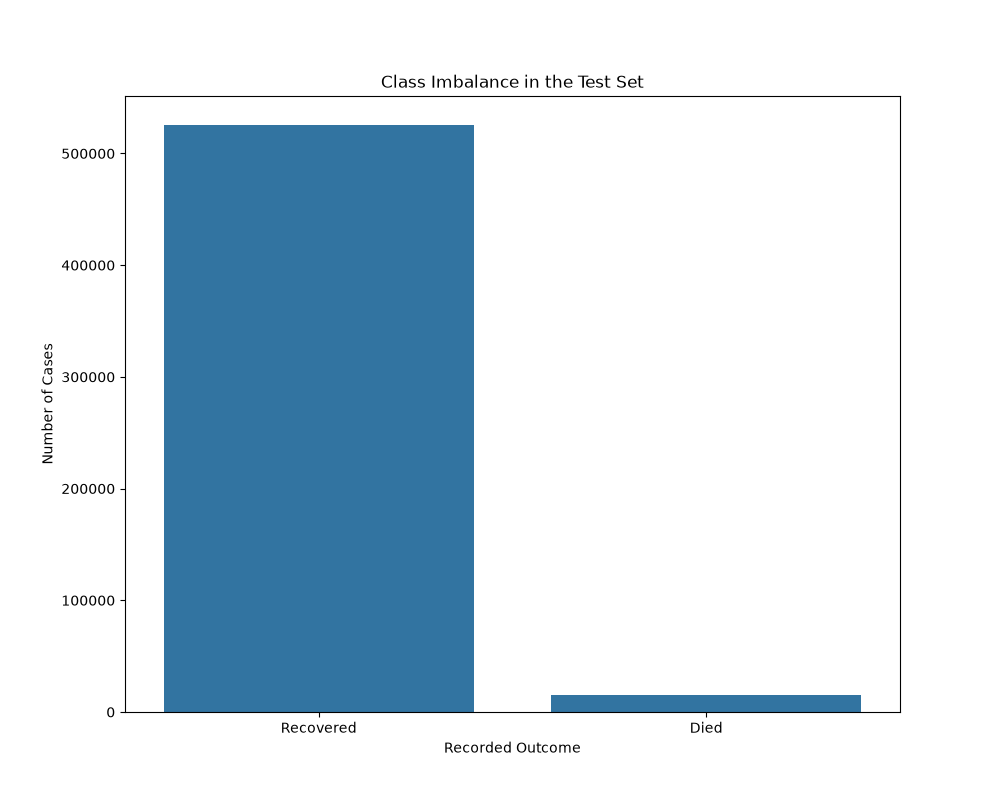

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

outcome_counts = pd.Series({"Recovered": test_weights[y_test == 0].sum(), "Died": test_weights[y_test == 1].sum(),})

plt.figure(figsize=(10, 8))
sns.barplot(x=outcome_counts.index, y=outcome_counts.values)
plt.title("Class Imbalance in the Test Set")
plt.xlabel("Recorded Outcome")
plt.ylabel("Number of Cases")
plt.show()


We can see that there are way more recovered cases compared to died cases causing a huge class imbalance. The model can just predict "recovered" for every case and still get a really good accuracy score.

## Validation Set


In [ ]:
# Cross validation set
fit_groups, val_groups = train_test_split(
    train_groups, test_size=0.25, random_state=42
)
fit_data = make_outcomes(fit_groups)
val_data = make_outcomes(val_groups)

# Balance the data
def balanced_weights(data):
    counts = data["patient_count"].groupby(data["death"]).transform("sum")
    return data["patient_count"] * (data["patient_count"].sum() / (2 * counts))

# One Hot Encode
val_encoder = OneHotEncoder(handle_unknown="ignore")
X_fit = val_encoder.fit_transform(fit_data[features])
X_val = val_encoder.transform(val_data[features])

# Check the best depth
validation_scores = {}
for depth in [2, 4, 6]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=42)
    candidate.fit(X_fit, fit_data["death"], sample_weight=balanced_weights(fit_data))
    validation_scores[depth] = f1_score(
        val_data["death"], candidate.predict(X_val),
        sample_weight=val_data["patient_count"], zero_division=0,
    )

best_depth = max(validation_scores, key=validation_scores.get)
print("Validation F1 by depth:", validation_scores)
print("Selected depth:", best_depth)


Validation F1 by depth: {2: 0.20340765103927966, 4: 0.20381993473546242, 6: 0.20381993473546242}
Selected depth: 4


## Evaluate the tuned tree

Refit the selected tree on the full original training set and score it on the original test set.

In [12]:
# Refit the model with the tuned depth
tuned_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
tuned_tree.fit(X_train_encoded, y_train, sample_weight=balanced_weights(train))
tuned_predictions = tuned_tree.predict(X_test_encoded)

# Get new scores
print("Accuracy:", accuracy_score(y_test, tuned_predictions, sample_weight=test_weights))
print("Precision:", precision_score(y_test, tuned_predictions, sample_weight=test_weights, zero_division=0))
print("Recall:", recall_score(y_test, tuned_predictions, sample_weight=test_weights, zero_division=0))
print("F1:", f1_score(y_test, tuned_predictions, sample_weight=test_weights, zero_division=0))


Accuracy: 0.7800599470055158
Precision: 0.11279660635858078
Recall: 0.9635083226632523
F1: 0.20195107550689048


The baseline tree achieved 97.1% accuracy by predicting recovery for every case. After tuning the tree depth and giving deaths more weight during training, test accuracy fell to 78.0%, but recall for deaths rose from 0% to 96.4% and F1 rose from 0 to 0.202. The tuned tree caught most deaths, though only 11.3% of its death predictions were correct.